In [ ]:
%pip install -q -U "scikit-learn>=1.7" catboost lightgbm


### настройки


In [ ]:
import os, gc, json, re, time, hashlib, itertools, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.special import softmax
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, ParameterGrid
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
from threadpoolctl import threadpool_limits
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

SEED = 42
OUTER = 5
INNER = 3
CROSSFIT = 3
THREADS = os.cpu_count() or 2
SVD_DIMS = [100]
DEPTHS = [4]
SVM_C = [.3]
THRESHOLDS = [-.5, 0., .5, 1.]
TURN_THRESHOLDS = [.25, .4, .5, .6, .75]
CLASSES = np.array(['negative', 'neutral', 'positive'])
DATA = Path('/content/hw1_train.jsonl')
OUTPUT = Path('/content/tree_experiments')
OUTPUT.mkdir(exist_ok=True)

PATTERNS = [
    r"\b(?:not|no|never|cannot|can't|don't|doesn't|didn't|isn't|wasn't)\b",
    r'\b(?:wrong|incorrect|false|inaccurate|disagree|mistake|error)\b',
    r'\b(?:fix|correct|revise|rewrite|redo|change|instead|still)\b',
    r'\b(?:explain|clarify|elaborate|detail|mean|understand)\b',
    r'\b(?:thanks|thank you|grateful|appreciate)\b',
    r'\b(?:great|perfect|excellent|helpful|works|awesome)\b',
    r'\b(?:sorry|apologize|apologise|apologies)\b',
    r"\b(?:you(?:'re| are) right|my mistake|i was wrong|i made (?:a |an )?(?:mistake|error)|i misunderstood)\b",
    r"\b(?:you(?:'re| are) welcome|glad (?:to|it)|happy to help)\b",
]
STRUCTURE = ['position', 'log_length', 'n_users', 'questions', 'exclamations']

try:
    import torch
except ImportError:
    torch = None
GPU = torch is not None and torch.cuda.is_available()
CAT_DEVICE = dict(task_type='GPU', devices='0') if GPU else dict(task_type='CPU')
print('CatBoost и SVD:', torch.cuda.get_device_name(0) if GPU else 'CPU; включи T4 в настройках среды')


CatBoost и SVD: CPU; включи T4 в настройках среды


In [ ]:
def folds(df, n):
    cv = StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=SEED)
    for tr, va in cv.split(df, df.reaction, df.group):
        assert not set(df.group.iloc[tr]) & set(df.group.iloc[va])
        yield tr, va


def group_data(df):
    from sklearn.neighbors import NearestNeighbors
    texts = df.turns.map(lambda ts: '\n'.join(t['text'] for t in ts if t['role'] == 'user'))
    x = TfidfVectorizer(max_features=10000, stop_words='english').fit_transform(texts)
    distances, neighbors = NearestNeighbors(n_neighbors=2, metric='cosine', algorithm='brute', n_jobs=THREADS).fit(x).kneighbors(x)
    parent = np.arange(len(df))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    for i, other in enumerate(neighbors[:, 1]):
        if i != other and 1 - distances[i, 1] >= .95:
            parent[find(other)] = find(i)
    return np.array([find(i) for i in range(len(df))])


def load_data(path=DATA):
    df = pd.read_json(path, lines=True)
    df['reaction'] = df.labels.map(lambda x: x.get('reaction') if isinstance(x, dict) else None)
    df = df[df.reaction.isin(CLASSES)].reset_index(drop=True)
    assert df.dialog_id.is_unique
    df['group'] = group_data(df)
    for row in df.itertuples():
        users = sum(t['role'] == 'user' for t in row.turns)
        assert len(row.labels['user_turns']) == users and users >= 2
        assert all(t.get('reaction') in CLASSES for t in row.labels['user_turns'][1:])
    return df


def pairs(df, training=False):
    rows = []
    for d, row in enumerate(df.to_dict('records')):
        turns = row['turns']; users = [i for i,t in enumerate(turns) if t['role']=='user']
        for j, i in enumerate(users[1:], 1):
            prev = turns[i-1] if i else {}; nxt = turns[i+1] if i+1<len(turns) else {}
            text = turns[i]['text']
            item = dict(dialog_pos=d, user=text, assistant=prev.get('text','') if prev.get('role')=='assistant' else '',
                        following=nxt.get('text','')[:600] if nxt.get('role')=='assistant' else '',
                        previous_length=len(prev.get('text','')) if prev.get('role')=='assistant' else 0,
                        following_length=len(nxt.get('text','')) if nxt.get('role')=='assistant' else 0,
                        position=j/max(len(users)-1,1), log_length=np.log1p(len(text)), n_users=len(users),
                        questions=text.count('?'), exclamations=text.count('!'))
            if training: item['reaction'] = row['labels']['user_turns'][j]['reaction']
            rows.append(item)
    return pd.DataFrame(rows)


def numeric(p):
    flags=[]; words={}
    for source in ['user','assistant','following']:
        texts=p[source].fillna('').str.lower()
        flags.extend(texts.str.contains(pattern,regex=True).to_numpy(dtype=np.float32) for pattern in PATTERNS)
        words[source]=[set(re.findall(r'\b\w+\b',s)) for s in texts]
    for a,b in [('user','assistant'),('user','following'),('assistant','following')]:
        flags.append(np.array([len(x&y)/max(len(x|y),1) for x,y in zip(words[a],words[b])],dtype=np.float32))
    signals=np.column_stack(flags).astype(np.float32)
    structure=p[STRUCTURE].to_numpy(dtype=np.float32)
    lengths=np.log1p(p[['previous_length','following_length']].to_numpy()).astype(np.float32)
    # Full = structure, assistant lengths, 30 role signals. Local omits the next answer.
    values=np.column_stack([structure,lengths,signals]).astype(np.float32)
    local=np.r_[0:6,7:25,34]  # excludes following length, following flags and its overlaps
    return values, signals, local


def encoder(mode):
    def word(n): return TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=n,sublinear_tf=True,dtype=np.float32)
    blocks=[('user_word',word(12000),'user'),('user_char',TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),min_df=3,max_features=18000,sublinear_tf=True,dtype=np.float32),'user')]
    weights={'user_word':1.,'user_char':1.}
    if mode != 'user':
        blocks += [('assistant',word(6000),'assistant'),('structure',StandardScaler(with_mean=False),STRUCTURE)]
        weights.update(assistant=.4,structure=.1)
    if mode == 'full':
        blocks += [('following',word(6000),'following')];weights['following']=.4
    return ColumnTransformer(blocks,transformer_weights=weights,sparse_threshold=1.)


def decision_weights(p):
    ids = p.dialog_pos.to_numpy(dtype=int)
    position = np.arange(len(p))
    last = np.full(ids.max()+1, -1, dtype=int)
    np.maximum.at(last, ids, np.where(p.reaction.to_numpy() != 'neutral', position, -1))
    decisive = last[ids]
    weights = np.where((decisive < 0) | (position >= decisive), 2., 1.)
    return weights / weights.mean()


def reduce_dialog(p,x,n):
    ids=p.dialog_pos.to_numpy(dtype=int);counts=np.bincount(ids,minlength=n)
    assert (counts>0).all()
    starts=np.r_[0,np.cumsum(counts)[:-1]];ends=starts+counts-1
    total=np.add.reduceat(x,starts,axis=0)
    return np.column_stack([total/counts[:,None],np.maximum.reduceat(x,starts,axis=0),x[ends],counts]).astype(np.float32)


def dialog_text(df):
    return df.turns.map(lambda ts:'\n'.join(t['text'] for t in ts if t['role']=='user')).tolist()


def aligned(model,x):
    prob=model.predict_proba(x)
    return np.asarray(prob[:,[list(model.classes_).index(k) for k in CLASSES]],dtype=np.float32)


def segment_last(mask, starts):
    return np.maximum.reduceat(np.where(mask, np.arange(len(mask)), -1), starts)


def last_reaction(p, prob, n, threshold=.5):
    ids = p.dialog_pos.to_numpy(dtype=int)
    counts = np.bincount(ids, minlength=n)
    assert (counts > 0).all()
    starts = np.r_[0, np.cumsum(counts)[:-1]]
    last = segment_last(np.maximum(prob[:, 0], prob[:, 2]) >= threshold, starts)
    selected = np.where(last >= 0, last, starts)
    return np.where(last >= 0, np.where(prob[selected, 2] > prob[selected, 0], 'positive', 'negative'), 'neutral')


def macro(y,pred):return f1_score(y,pred,labels=CLASSES,average='macro',zero_division=0)


def learner(family,params):
    p=dict(params)
    if family=='tree':return DecisionTreeClassifier(**p,random_state=SEED)
    if family=='bagging':
        depth=p.pop('depth');return BaggingClassifier(DecisionTreeClassifier(max_depth=depth),**p,n_jobs=THREADS,random_state=SEED)
    if family=='forest':return RandomForestClassifier(**p,max_features='sqrt',n_jobs=THREADS,random_state=SEED)
    if family=='hgb':return HistGradientBoostingClassifier(max_depth=p['depth'],learning_rate=p['learning_rate'],max_iter=p['iterations'],early_stopping=False,random_state=SEED)
    if family=='lightgbm':return LGBMClassifier(max_depth=p['depth'],num_leaves=2**p['depth'],learning_rate=p['learning_rate'],n_estimators=p['iterations'],n_jobs=THREADS,verbosity=-1,random_state=SEED)
    if family=='catboost':return CatBoostClassifier(depth=p['depth'],learning_rate=p['learning_rate'],iterations=p['iterations'],thread_count=THREADS,verbose=False,allow_writing_files=False,random_seed=SEED,**CAT_DEVICE)
    if family=='lr':return Pipeline([('scale',StandardScaler(with_mean=False)),('model',LogisticRegression(**p,max_iter=2000,random_state=SEED))])
    if family=='mlp':return Pipeline([('scale',StandardScaler()),('model',MLPClassifier(hidden_layer_sizes=(128,64),**p,max_iter=500,early_stopping=False,random_state=SEED))])


def fit_weighted(model,x,y):
    w=compute_sample_weight('balanced',y)
    if isinstance(model,Pipeline):
        # MLP support for sample_weight depends on sklearn; require a recent release.
        model.fit(x,y,model__sample_weight=w)
    else:model.fit(x,y,sample_weight=w)
    return model


### модели и oof


In [ ]:
class SparseSVD:
    def __init__(self, n_components, random_state=42):
        self.n_components = n_components
        self.random_state = random_state

    def _gpu_matrix(self, x):
        coo = sparse.coo_matrix(x, dtype=np.float32)
        indices = np.vstack([coo.row, coo.col]).astype(np.int64)
        return torch.sparse_coo_tensor(
            torch.from_numpy(indices).to('cuda'),
            torch.from_numpy(coo.data).to('cuda'),
            size=coo.shape, device='cuda',
        ).coalesce()

    def fit(self, x):
        if not GPU:
            self.cpu = TruncatedSVD(self.n_components, random_state=self.random_state).fit(x)
            return self
        # All large multiplications stay sparse. Only a small basis becomes dense.
        with torch.no_grad():
            torch.manual_seed(self.random_state)
            a = self._gpu_matrix(x)
            at = a.transpose(0, 1).coalesce()
            q = min(self.n_components + 10, min(x.shape))
            omega = torch.randn(x.shape[1], q, device='cuda', dtype=torch.float32)
            basis = torch.linalg.qr(torch.sparse.mm(a, omega), mode='reduced')[0]
            for _ in range(5):
                right = torch.linalg.qr(torch.sparse.mm(at, basis), mode='reduced')[0]
                basis = torch.linalg.qr(torch.sparse.mm(a, right), mode='reduced')[0]
            small = torch.sparse.mm(at, basis).T
            _, _, vh = torch.linalg.svd(small, full_matrices=False)
            self.components_ = vh[:self.n_components].cpu().numpy().copy()
        return self

    def transform(self, x):
        if not GPU:
            return self.cpu.transform(x).astype(np.float32)
        with torch.no_grad():
            components = torch.as_tensor(self.components_.T.copy(), device='cuda')
            output = torch.sparse.mm(self._gpu_matrix(x), components).cpu().numpy()
        return output


# One shared representation per training split; no hyperparameter search.
FIXED = {
    'Tree': ('tree', dict(max_depth=6, min_samples_leaf=10)),
    'Bagging': ('bagging', dict(depth=None, n_estimators=100)),
    'Forest': ('forest', dict(max_depth=None, min_samples_leaf=3, n_estimators=100)),
    'HGB': ('hgb', dict(depth=4, learning_rate=.07, iterations=200)),
    'LightGBM': ('lightgbm', dict(depth=4, learning_rate=.07, iterations=200)),
    'CatBoost': ('catboost', dict(depth=4, learning_rate=.07, iterations=200)),
}
STACK_BASES = ['Decision_fixed', 'LR_dialog', 'Forest', 'LightGBM', 'CatBoost']
SVD_DIM = 100


class CompactText:
    def __init__(self, dialog_dense=True):
        self.dialog_dense = dialog_dense

    def fit_transform(self, train):
        p = pairs(train)
        self.turn = encoder('full')
        self.turn.transformers = [t for t in self.turn.transformers if t[0] != 'structure']
        self.turn.transformer_weights.pop('structure')
        raw = sparse.csr_matrix(self.turn.fit_transform(p))
        self.svd = SparseSVD(min(SVD_DIM, min(raw.shape)-1), random_state=SEED).fit(raw)
        self.dialog = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=24000,
                                     sublinear_tf=True, dtype=np.float32)
        dx = self.dialog.fit_transform(dialog_text(train))
        self.dialog_svd = SparseSVD(min(SVD_DIM, min(dx.shape)-1), random_state=SEED).fit(dx) if self.dialog_dense else None
        num, signals, _ = numeric(p)
        self.signal_scale = StandardScaler(with_mean=False).fit(sparse.csr_matrix(signals))
        self.structure_scale = StandardScaler(with_mean=False).fit(p[STRUCTURE])
        self.structure_at = self.turn.output_indices_['assistant'].stop
        return self._assemble(p, raw, dx, num, signals)

    def _assemble(self, p, raw, dx, num, signals):
        z = self.svd.transform(raw).astype(np.float32)
        turn = np.column_stack([z, num]).astype(np.float32)
        dialog = None
        if self.dialog_svd is not None:
            dz = self.dialog_svd.transform(dx).astype(np.float32)
            dialog = np.column_stack([dz, reduce_dialog(p, num, dx.shape[0])]).astype(np.float32)
        # Reuse TF-IDF blocks. Only insert structure before following and append signals.
        k = self.structure_at
        svm = sparse.hstack([
            raw[:, :k], self.structure_scale.transform(p[STRUCTURE]) * .1, raw[:, k:],
            self.signal_scale.transform(sparse.csr_matrix(signals)) * .1,
        ], format='csr')
        return dict(pairs=p, raw=raw, turn=turn, dialog=dialog, dialog_raw=dx, svm=svm)

    def transform(self, df):
        p = pairs(df)
        raw = sparse.csr_matrix(self.turn.transform(p))
        dx = self.dialog.transform(dialog_text(df))
        num, signals, _ = numeric(p)
        return self._assemble(p, raw, dx, num, signals)


def fit_fixed(train, names=None):
    from concurrent.futures import ThreadPoolExecutor
    train = train.reset_index(drop=True)
    names = set(names) if names is not None else set(FIXED) | {'Decision_fixed', 'LR_dialog', 'CatBoost_dialog', 'Tree_tfidf', 'Forest_tfidf'}
    representation = CompactText(dialog_dense='CatBoost_dialog' in names)
    f = representation.fit_transform(train)
    training_pairs = f['pairs'].copy()
    training_pairs['reaction'] = np.concatenate([
        np.array([t['reaction'] for t in labels['user_turns'][1:]]) for labels in train.labels
    ])
    target = training_pairs.reaction.to_numpy()
    weights = decision_weights(training_pairs)

    def cpu_impl():
        models = {}
        for name, (family, params) in FIXED.items():
            if name in names and not (GPU and family == 'catboost'):
                models[name] = fit_weighted(learner(family, params), f['turn'], target)
        for name, kind, family in [('Tree_tfidf','raw','tree'), ('Forest_tfidf','raw','forest')]:
            if name in names:
                models[name] = fit_weighted(learner(family, FIXED[family.title()][1]), f[kind], target)
        if 'LR_dialog' in names:
            models['LR_dialog'] = fit_weighted(learner('lr', dict(C=1.)), f['dialog_raw'], train.reaction)
        binary = {}
        for label in ['negative', 'positive']:
            model = LinearSVC(C=.3, class_weight='balanced', dual=False, max_iter=10000, random_state=SEED)
            model.fit(f['svm'], target==label, sample_weight=weights)
            scale = max(float(np.std(model.decision_function(f['svm']))), 1e-6)
            binary[label] = model, scale
        return models, binary

    def cpu_models():
        # OpenMP limits must also be set in the worker thread.
        with threadpool_limits(limits=THREADS):
            return cpu_impl()

    # One CPU training stream, one GPU stream. No parallel GPU fits or matrix copies.
    gpu_models = {}
    if GPU:
        with ThreadPoolExecutor(max_workers=1) as pool:
            pending = pool.submit(cpu_models)
            if 'CatBoost' in names:
                gpu_models['CatBoost'] = fit_weighted(learner('catboost', FIXED['CatBoost'][1]), f['turn'], target)
            if 'CatBoost_dialog' in names:
                gpu_models['CatBoost_dialog'] = fit_weighted(learner('catboost', FIXED['CatBoost'][1]), f['dialog'], train.reaction)
            models, binary = pending.result()
        models.update(gpu_models)
    else:
        models, binary = cpu_models()
        if 'CatBoost_dialog' in names:
            models['CatBoost_dialog'] = fit_weighted(learner('catboost', FIXED['CatBoost'][1]), f['dialog'], train.reaction)
    # Stable output order even when CPU and GPU finish at different times.
    order = [*FIXED, 'Tree_tfidf', 'Forest_tfidf', 'LR_dialog', 'CatBoost_dialog']
    models = {name: models[name] for name in order if name in models}
    return dict(representation=representation, models=models, binary=binary, train_ids=train.dialog_id.tolist())


def predict_fixed(bundle, valid):
    f = bundle['representation'].transform(valid[['dialog_id', 'turns']].reset_index(drop=True))
    p = f['pairs']; n = len(valid)
    margins = {label: model.decision_function(f['svm'])/scale for label,(model,scale) in bundle['binary'].items()}
    ids = p.dialog_pos.to_numpy(dtype=int)
    counts = np.bincount(ids, minlength=n)
    assert (counts > 0).all()
    starts = np.r_[0, np.cumsum(counts)[:-1]]
    found = (margins['positive'] >= 0) | (margins['negative'] >= 0)
    last = segment_last(found, starts)
    selected = np.where(last >= 0, last, starts)
    pred = np.where(last >= 0, np.where(margins['positive'][selected] > margins['negative'][selected], 'positive', 'negative'), 'neutral')
    score = np.column_stack([margins['negative'][selected], np.zeros(n), margins['positive'][selected]])
    predictions = {'Decision_fixed': pred}
    probabilities = {'Decision_fixed': softmax(score, axis=1).astype(np.float32)}
    turn_prob = {}
    for name, model in bundle['models'].items():
        kind = 'dialog_raw' if name=='LR_dialog' else 'dialog' if name=='CatBoost_dialog' else 'raw' if name.endswith('_tfidf') else 'turn'
        prob = aligned(model, f[kind])
        if kind in ['raw', 'turn']:
            last = segment_last(np.maximum(prob[:, 0], prob[:, 2]) >= .5, starts)
            sel = np.where(last >= 0, last, starts)
            predictions[name] = np.where(last >= 0, np.where(prob[sel, 2] > prob[sel, 0], 'positive', 'negative'), 'neutral')
            probabilities[name] = prob[sel]
            turn_prob[name] = prob
        else:
            predictions[name]=CLASSES[prob.argmax(axis=1)];probabilities[name]=prob
    return predictions, probabilities, turn_prob


_raw_pairs = getattr(pairs, "_uncached", pairs)
_raw_numeric = getattr(numeric, "_uncached", numeric)
STATIC = None


def prepare_static(df):
    global STATIC
    p = _raw_pairs(df)
    values, signals, local = _raw_numeric(p)
    counts = np.bincount(p.dialog_pos.to_numpy(dtype=int), minlength=len(df))
    starts = np.r_[0, np.cumsum(counts)[:-1]]
    locations = {key: np.arange(start, start+count) for key, start, count in zip(df.dialog_id, starts, counts)}
    STATIC = dict(pairs=p.drop(columns='dialog_pos'), values=values, signals=signals,
                  local=local, locations=locations,
                  texts={row.dialog_id: '\n'.join(t['text'] for t in row.turns if t['role']=='user')
                         for row in df.itertuples()})


def pairs(df, training=False):
    if STATIC is None or not set(df.dialog_id) <= STATIC['locations'].keys():
        return _raw_pairs(df, training)
    locations = [STATIC['locations'][key] for key in df.dialog_id]
    idx = np.concatenate(locations)
    p = STATIC['pairs'].iloc[idx].reset_index(drop=True).copy()
    p['dialog_pos'] = np.repeat(np.arange(len(df)), [len(v) for v in locations])
    p['_static_row'] = idx
    if training:
        p['reaction'] = np.concatenate([np.array([t['reaction'] for t in labels['user_turns'][1:]]) for labels in df.labels])
    return p


def numeric(p):
    if STATIC is None or '_static_row' not in p:
        return _raw_numeric(p)
    idx = p['_static_row'].to_numpy(dtype=int)
    return STATIC['values'][idx], STATIC['signals'][idx], STATIC['local']


def dialog_text(df):
    if STATIC is not None and set(df.dialog_id) <= STATIC['texts'].keys():
        return [STATIC['texts'][key] for key in df.dialog_id]
    return df.turns.map(lambda ts: '\n'.join(t['text'] for t in ts if t['role']=='user')).tolist()


pairs._uncached = _raw_pairs
numeric._uncached = _raw_numeric


def run_key(df):
    import inspect, marshal, sklearn, catboost, lightgbm
    functions = [folds, _raw_pairs, _raw_numeric, pairs, numeric, dialog_text, decision_weights,
                 encoder, learner, fit_weighted, fit_fixed, predict_fixed, prepare_static, run_fixed,
                 reduce_dialog, last_reaction, segment_last, aligned, macro, run_key]
    chunks = []
    for obj in [*functions, CompactText, SparseSVD]:
        try:
            chunks.append(inspect.getsource(obj).encode())
        except (OSError, TypeError):
            if isinstance(obj, type):
                chunks.extend(marshal.dumps(v.__code__) for v in obj.__dict__.values() if callable(v) and hasattr(v,'__code__'))
            else:
                chunks.append(marshal.dumps(obj.__code__))
    data = df[['dialog_id', 'turns', 'labels', 'reaction', 'group']].to_json(orient='records')
    config = repr((FIXED, STACK_BASES, SVD_DIM, OUTER, INNER, GPU, THREADS, PATTERNS, STRUCTURE, CLASSES.tolist(),
                   sklearn.__version__, catboost.__version__, lightgbm.__version__, np.__version__,
                   torch.__version__ if torch is not None else None,
                   torch.cuda.get_device_name(0) if GPU else None))
    return hashlib.sha256(b''.join(chunks)+data.encode()+config.encode()).hexdigest()


def run_fixed(df):
    import joblib
    prepare_static(df)
    key = run_key(df)
    run_dir = OUTPUT / key[:16]
    run_dir.mkdir(exist_ok=True)
    predictions={};metrics=[];turn_diagnostics=[]
    for fold,(tr,va) in enumerate(folds(df,OUTER),1):
        start=time.perf_counter()
        checkpoint = run_dir / f'fold{fold}.joblib'
        if checkpoint.exists():
            cached = joblib.load(checkpoint)
            assert cached['key'] == key and cached['valid_ids'] == df.iloc[va].dialog_id.tolist()
            pred, tp = cached['predictions'], cached['turn_prob']
            valid = df.iloc[va][['dialog_id','turns']].reset_index(drop=True)
        else:
            train=df.iloc[tr].reset_index(drop=True)
            valid=df.iloc[va][['dialog_id','turns']].reset_index(drop=True)
            oof={name:np.full((len(train),3),np.nan,dtype=np.float32) for name in STACK_BASES}
            # Fixed parameters: the same inner models serve the OOF stack. No extra tuning layer.
            for it,iv in folds(train,INNER):
                fit=train.iloc[it].reset_index(drop=True)
                check=train.iloc[iv][['dialog_id','turns']].reset_index(drop=True)
                bundle=fit_fixed(fit, names=STACK_BASES);_,prob,_=predict_fixed(bundle,check)
                for name in STACK_BASES:oof[name][iv]=prob[name]
                del bundle
                gc.collect()
            assert all(np.isfinite(v).all() for v in oof.values())
            bundle=fit_fixed(train);pred,prob,tp=predict_fixed(bundle,valid)
            for family in ['lr','catboost']:
                params=dict(C=1.) if family=='lr' else dict(depth=3,learning_rate=.07,iterations=150)
                meta=fit_weighted(learner(family,params),np.column_stack([oof[k] for k in STACK_BASES]),train.reaction)
                pred['Stack_'+family]=np.asarray(meta.predict(np.column_stack([prob[k] for k in STACK_BASES]))).reshape(-1)
            for dropped in STACK_BASES:
                keep=[k for k in STACK_BASES if k!=dropped]
                meta=fit_weighted(learner('lr',dict(C=1.)),np.column_stack([oof[k] for k in keep]),train.reaction)
                pred['Stack_without_'+dropped]=meta.predict(np.column_stack([prob[k] for k in keep]))
            joblib.dump(dict(key=key, valid_ids=valid.dialog_id.tolist(), predictions=pred, turn_prob=tp), checkpoint, compress=3)
            del bundle
        for name,p in pred.items():
            if name not in predictions:predictions[name]=np.full(len(df),'',dtype=object)
            predictions[name][va]=p
            metrics.append(dict(model=name,fold=fold,macro_f1=macro(df.reaction.to_numpy()[va],p)))
        turn_diagnostics.append(dict(fold=fold,ids=valid.dialog_id.tolist(),turn_prob=tp))
        result=dict(predictions=predictions,fold_scores=pd.DataFrame(metrics),ids=df.dialog_id.tolist(),y=df.reaction.to_numpy(),diagnostics=turn_diagnostics, run_key=key)
        joblib.dump(result,OUTPUT/'fixed_progress.joblib',compress=3)
        elapsed=(time.perf_counter()-start)/60
        print('фолд',fold,'из',OUTER,'минут:',round(elapsed,1),'осталось примерно:',round(elapsed*(OUTER-fold),1),flush=True)
        gc.collect()
    assert all((p!='').all() for p in predictions.values())
    table=pd.DataFrame([dict(model=name,macro_f1=macro(df.reaction,p),accuracy=accuracy_score(df.reaction,p),
                            mean_cv_macro_f1=result['fold_scores'].query('model == @name').macro_f1.mean())
                        for name,p in predictions.items()]).set_index('model')
    result['table']=table;table.to_csv(OUTPUT/'fixed_comparison.csv')
    joblib.dump(result,OUTPUT/'fixed_results.joblib',compress=3)
    return result


### запуск


In [ ]:
df = load_data()
display(df.reaction.value_counts())
start = time.perf_counter()
with threadpool_limits(limits=THREADS):
    result = run_fixed(df)
display(result['table'].sort_values('macro_f1', ascending=False).round(4))
display(result['fold_scores'].pivot(index='fold', columns='model', values='macro_f1').round(4))
print('всего минут:', round((time.perf_counter()-start)/60, 1))


,count
reaction,
neutral,1774
negative,923
positive,303


фолд 1 из 5 минут: 7.5 осталось примерно: 30.2
фолд 2 из 5 минут: 7.6 осталось примерно: 22.7
фолд 3 из 5 минут: 7.3 осталось примерно: 14.6
фолд 4 из 5 минут: 7.2 осталось примерно: 7.2
фолд 5 из 5 минут: 7.0 осталось примерно: 0.0


,macro_f1,accuracy,mean_cv_macro_f1
model,,,
Forest_tfidf,0.7110,0.7733,0.7109
Forest,0.6999,0.7690,0.6992
Decision_fixed,0.6954,0.7483,0.6953
Stack_without_CatBoost,0.6905,0.7430,0.6906
LightGBM,0.6904,0.7377,0.6901
HGB,0.6876,0.7393,0.6872
Stack_without_LightGBM,0.6865,0.7397,0.6866
Stack_without_Forest,0.6859,0.7357,0.6857
Stack_without_LR_dialog,0.6850,0.7370,0.6848


model,Bagging,CatBoost,CatBoost_dialog,Decision_fixed,Forest,Forest_tfidf,HGB,LR_dialog,LightGBM,Stack_catboost,Stack_lr,Stack_without_CatBoost,Stack_without_Decision_fixed,Stack_without_Forest,Stack_without_LR_dialog,Stack_without_LightGBM,Tree,Tree_tfidf
fold,,,,,,,,,,,,,,,,,,
1,0.6866,0.6853,0.6618,0.6847,0.7117,0.7283,0.7050,0.5357,0.7017,0.6973,0.6854,0.6852,0.6808,0.6955,0.6922,0.6837,0.6423,0.6063
2,0.6828,0.6664,0.6798,0.7028,0.7163,0.7166,0.6945,0.4999,0.6966,0.6723,0.6926,0.7030,0.6776,0.6884,0.6923,0.6968,0.5759,0.6124
3,0.6568,0.6623,0.6859,0.7065,0.6910,0.7103,0.6841,0.4765,0.6981,0.6964,0.6933,0.7129,0.6755,0.6887,0.6873,0.6901,0.5872,0.5900
4,0.6986,0.6732,0.6434,0.6916,0.7058,0.7068,0.6833,0.4621,0.6863,0.6627,0.6740,0.6700,0.6661,0.6889,0.6808,0.6762,0.4419,0.5014
5,0.6743,0.6696,0.6414,0.6910,0.6711,0.6924,0.6694,0.5072,0.6678,0.6695,0.6688,0.6822,0.6601,0.6668,0.6715,0.6861,0.6110,0.5948


всего минут: 37.4


### ошибки


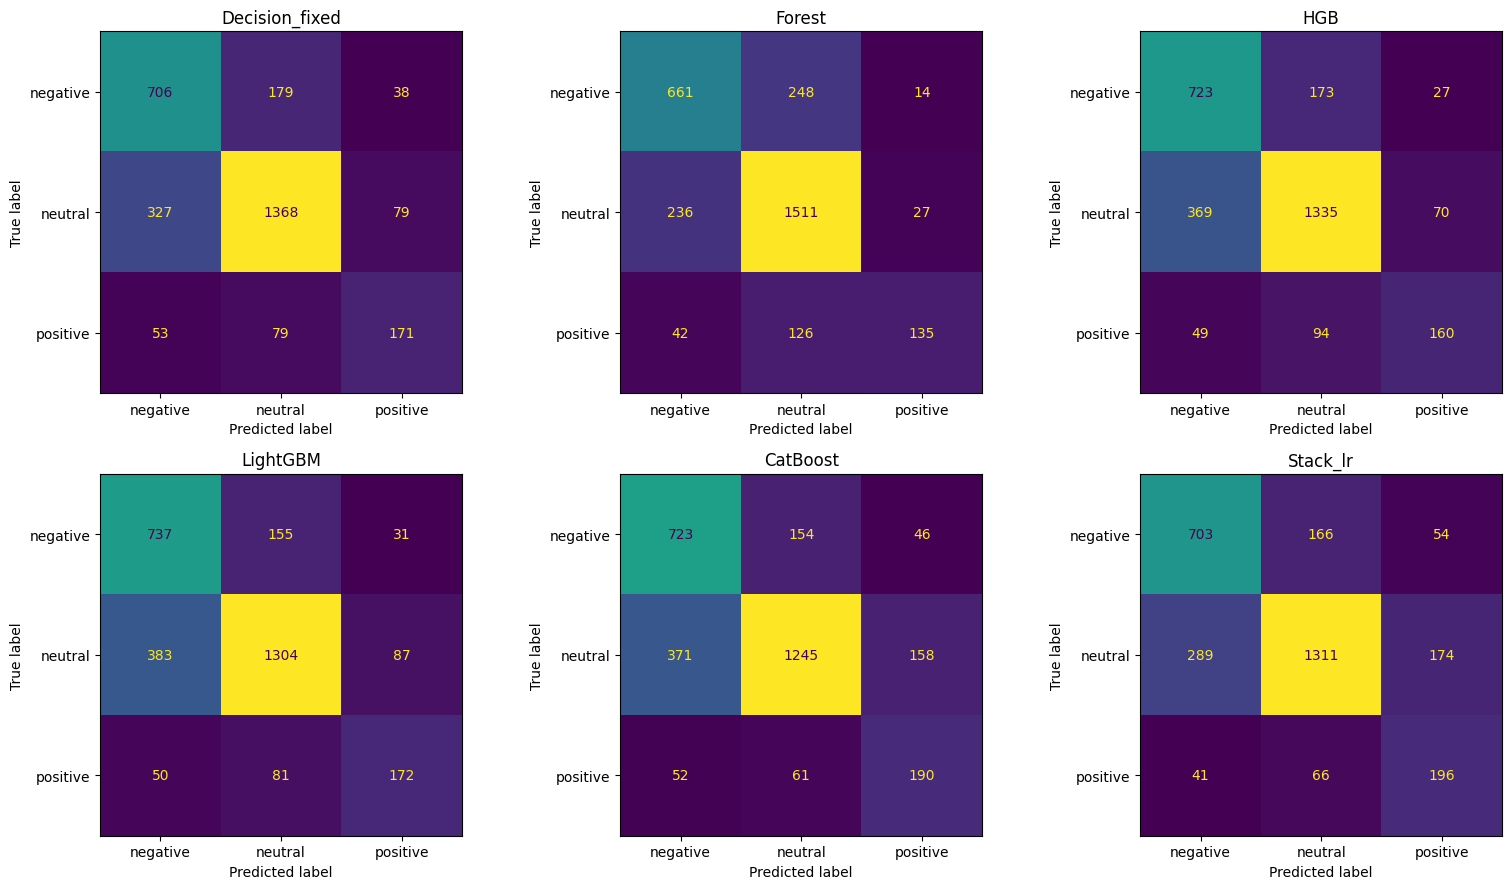

Decision_fixed


,precision,recall,f1-score,support
negative,0.6501,0.7649,0.7028,923.0000
neutral,0.8413,0.7711,0.8047,1774.0000
positive,0.5938,0.5644,0.5787,303.0000
accuracy,0.7483,0.7483,0.7483,0.7483
macro avg,0.6951,0.7001,0.6954,3000.0000
weighted avg,0.7575,0.7483,0.7505,3000.0000


Forest


,precision,recall,f1-score,support
negative,0.7039,0.7161,0.7100,923.000
neutral,0.8016,0.8517,0.8259,1774.000
positive,0.7670,0.4455,0.5637,303.000
accuracy,0.7690,0.7690,0.7690,0.769
macro avg,0.7575,0.6711,0.6999,3000.000
weighted avg,0.7681,0.7690,0.7638,3000.000


HGB


,precision,recall,f1-score,support
negative,0.6337,0.7833,0.7006,923.0000
neutral,0.8333,0.7525,0.7909,1774.0000
positive,0.6226,0.5281,0.5714,303.0000
accuracy,0.7393,0.7393,0.7393,0.7393
macro avg,0.6965,0.6880,0.6876,3000.0000
weighted avg,0.7506,0.7393,0.7409,3000.0000


... (2 outputs left out)

CatBoost


,precision,recall,f1-score,support
negative,0.6309,0.7833,0.6989,923.0000
neutral,0.8527,0.7018,0.7699,1774.0000
positive,0.4822,0.6271,0.5452,303.0000
accuracy,0.7193,0.7193,0.7193,0.7193
macro avg,0.6553,0.7041,0.6713,3000.0000
weighted avg,0.7471,0.7193,0.7254,3000.0000


Stack_lr


,precision,recall,f1-score,support
negative,0.6805,0.7616,0.7188,923.0000
neutral,0.8496,0.7390,0.7905,1774.0000
positive,0.4623,0.6469,0.5392,303.0000
accuracy,0.7367,0.7367,0.7367,0.7367
macro avg,0.6641,0.7158,0.6828,3000.0000
weighted avg,0.7585,0.7367,0.7430,3000.0000


In [ ]:
names = ['Decision_fixed', 'Forest', 'HGB', 'LightGBM', 'CatBoost', 'Stack_lr']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.flat, names):
    ConfusionMatrixDisplay.from_predictions(result['y'], result['predictions'][name], labels=CLASSES, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()
for name in names:
    print(name)
    display(pd.DataFrame(classification_report(result['y'], result['predictions'][name], labels=CLASSES,
                         output_dict=True, zero_division=0)).T.round(4))


### извинения ассистента


In [ ]:
rows = []
for part in result['diagnostics']:
    valid = df.set_index('dialog_id').loc[part['ids']].reset_index()
    p = pairs(valid, True)
    apology = p.following.str.lower().str.contains(PATTERNS[6], regex=True).to_numpy()
    for name, prob in part['turn_prob'].items():
        detected = np.maximum(prob[:,0], prob[:,2]) >= .5
        neutral = p.reaction.to_numpy() == 'neutral'
        for flag in [False, True]:
            mask = apology == flag
            rows.append(dict(model=name, apology=flag, n=int(mask.sum()),
                             neutral=int((mask & neutral).sum()), nonneutral=int((mask & ~neutral).sum()),
                             false_positive=int((mask & neutral & detected).sum()),
                             missed=int((mask & ~neutral & ~detected).sum())))
apology_table = pd.DataFrame(rows).groupby(['model','apology']).sum()
apology_table['false_positive_rate'] = apology_table.false_positive / apology_table.neutral
apology_table['recall_nonneutral'] = 1 - apology_table.missed / apology_table.nonneutral
display(apology_table.round(4))
apology_table.to_csv(OUTPUT / 'fixed_apology_errors.csv')


n  neutral  nonneutral  false_positive  missed  \
model        apology                                                       
Bagging      False    15067    13403        1664             378    1169   
             True      1984      696        1288             578      57   
CatBoost     False    15067    13403        1664             996     910   
             True      1984      696        1288             623      27   
Forest       False    15067    13403        1664             326    1153   
             True      1984      696        1288             430     118   
Forest_tfidf False    15067    13403        1664             396    1086   
             True      1984      696        1288             319     213   
HGB          False    15067    13403        1664             706     919   
             True      1984      696        1288             482      64   
LightGBM     False    15067    13403        1664             795     890   
             True      1984      696        1288             542      48   
Tree         False    15067    13403        1664            1839     968   
             True      1984      696        1288             663      20   
Tree_tfidf   False    15067    13403        1664            1702     964   
             True      1984      696        1288             493     136   

                      false_positive_rate  recall_nonneutral  
model        apology                                          
Bagging      False                 0.0282             0.2975  
             True                  0.8305             0.9557  
CatBoost     False                 0.0743             0.4531  
             True                  0.8951             0.9790  
Forest       False                 0.0243             0.3071  
             True                  0.6178             0.9084  
Forest_tfidf False                 0.0295             0.3474  
             True                  0.4583             0.8346  
HGB          False                 0.0527             0.4477  
             True                  0.6925             0.9503  
LightGBM     False                 0.0593             0.4651  
             True                  0.7787             0.9627  
Tree         False                 0.1372             0.4183  
             True                  0.9526             0.9845  
Tree_tfidf   False                 0.1270             0.4207  
             True                  0.7083             0.8944

In [ ]:
import joblib
from IPython.display import display
if 'df' not in globals():
    df = load_data()
if 'result' not in globals():
    result = joblib.load(OUTPUT / 'fixed_results.joblib')
previous = result
assert previous['ids'] == df.dialog_id.tolist()
assert np.array_equal(previous['y'], df.reaction.to_numpy())
for part, (tr, va) in zip(previous['diagnostics'], folds(df, OUTER)):
    assert part['ids'] == df.iloc[va].dialog_id.tolist()
    valid = df.iloc[va][['dialog_id','turns']].reset_index(drop=True)
    check = last_reaction(pairs(valid), part['turn_prob']['Forest_tfidf'], len(valid), .5)
    assert np.array_equal(check, np.asarray(previous['predictions']['Forest_tfidf'])[va])
print('готовые оценки и фолды совпали')


готовые оценки и фолды совпали


,macro_f1,equal_prior_macro_f1
model,,
Forest_tfidf,0.7110,0.6812
Forest,0.6999,0.6653
Decision_fixed,0.6954,0.6990
Stack_without_CatBoost,0.6905,0.7207
LightGBM,0.6904,0.6994
HGB,0.6876,0.6860
Stack_without_LightGBM,0.6865,0.7192
Stack_without_Forest,0.6859,0.7235
Stack_without_LR_dialog,0.6850,0.7203


Forest_tfidf


,precision,recall,f1-score,support
negative,0.7261,0.6836,0.7042,923.0000
neutral,0.7973,0.8670,0.8307,1774.0000
positive,0.7475,0.4983,0.5980,303.0000
accuracy,0.7733,0.7733,0.7733,0.7733
macro avg,0.7570,0.6830,0.7110,3000.0000
weighted avg,0.7704,0.7733,0.7683,3000.0000


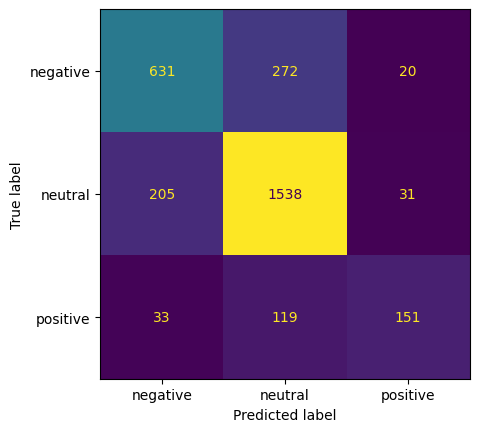

In [ ]:
metric_rows = []
y = np.asarray(previous['y'])
w = compute_sample_weight('balanced', y)
for name, pred in previous['predictions'].items():
    metric_rows.append(dict(model=name, macro_f1=macro(y,pred),
        equal_prior_macro_f1=f1_score(y,pred,labels=CLASSES,average='macro',sample_weight=w,zero_division=0)))
prior_table = pd.DataFrame(metric_rows).set_index('model')
display(prior_table.sort_values('macro_f1',ascending=False).round(4))
print('Forest_tfidf')
display(pd.DataFrame(classification_report(y,previous['predictions']['Forest_tfidf'],labels=CLASSES,
                     output_dict=True,zero_division=0)).T.round(4))
ConfusionMatrixDisplay.from_predictions(y,previous['predictions']['Forest_tfidf'],labels=CLASSES,colorbar=False)
plt.show()
prior_table.to_csv(OUTPUT/'prior_comparison.csv')


In [ ]:
# Saved outer scores are reused. Only missing inner scores and newly selected models are fitted.
RF_CASES = {
    'base': dict(n_estimators=100, max_depth=None, min_samples_leaf=3, max_features='sqrt'),
    'leaf1': dict(n_estimators=100, max_depth=None, min_samples_leaf=1, max_features='sqrt'),
    'leaf6': dict(n_estimators=100, max_depth=None, min_samples_leaf=6, max_features='sqrt'),
    'depth20': dict(n_estimators=100, max_depth=20, min_samples_leaf=3, max_features='sqrt'),
    'features01': dict(n_estimators=100, max_depth=None, min_samples_leaf=3, max_features=.1),
    'unweighted': dict(n_estimators=100, max_depth=None, min_samples_leaf=3, max_features='sqrt'),
    'trees200': dict(n_estimators=200, max_depth=None, min_samples_leaf=3, max_features='sqrt'),
}
COMBINATIONS = {
    'Forest_SVM_LGB': ['Forest_tfidf', 'Decision_fixed', 'LightGBM'],
    'Forest_SVM_Cat': ['Forest_tfidf', 'Decision_fixed', 'CatBoost'],
    'Forest_SVM_LGB_Cat': ['Forest_tfidf', 'Decision_fixed', 'LightGBM', 'CatBoost'],
}


def addon_representation(train):
    # Compatible with earlier and current versions of the notebook.
    import inspect
    rep = CompactText(dialog_dense=False) if 'dialog_dense' in inspect.signature(CompactText).parameters else CompactText()
    if hasattr(rep, 'fit_transform'):
        f = rep.fit_transform(train)
    else:
        rep.fit(train)
        f = rep.transform(train)
    return rep, f


def addon_svm(train, f):
    training_pairs = pairs(train, True)
    target = training_pairs.reaction.to_numpy()
    weights = decision_weights(training_pairs)
    models = {}
    for label in ['negative', 'positive']:
        model = LinearSVC(C=.3, class_weight='balanced', dual=False, max_iter=10000, random_state=SEED)
        model.fit(f['svm'], target == label, sample_weight=weights)
        models[label] = model, max(float(np.std(model.decision_function(f['svm']))), 1e-6)
    return models


def svm_turn_prob(models, f):
    margin = {label: model.decision_function(f['svm']) / scale for label, (model, scale) in models.items()}
    return softmax(np.column_stack([margin['negative'], np.zeros(len(f['pairs'])), margin['positive']]), axis=1).astype(np.float32)


def turn_to_dialog(p, prob, n, rule=('last', 1., 1., .5)):
    mode, wn, wp, threshold = rule
    adjusted = prob * np.array([wn, 1., wp], dtype=np.float32)
    adjusted = adjusted / adjusted.sum(axis=1, keepdims=True)
    ids = p.dialog_pos.to_numpy(dtype=int)
    counts = np.bincount(ids, minlength=n)
    assert (counts > 0).all()
    starts = np.r_[0, np.cumsum(counts)[:-1]]
    if mode == 'soft':
        state = np.zeros((n, 3)); state[:, 1] = 1.
        for position in range(int(counts.max())):
            active = np.flatnonzero(counts > position)
            values = adjusted[starts[active] + position]
            previous = state[active]
            state[active] = values[:, 1, None] * previous
            state[active, 0] += values[:, 0]
            state[active, 2] += values[:, 2]
        return CLASSES[state.argmax(axis=1)], state
    sign = np.where(adjusted[:, 2] > adjusted[:, 0], 2, 0)
    detected = adjusted.argmax(axis=1) != 1 if mode == 'argmax' else np.maximum(adjusted[:, 0], adjusted[:, 2]) >= threshold
    indices = np.arange(len(p))
    last = np.maximum.reduceat(np.where(detected, indices, -1), starts)
    selected = np.where(last >= 0, last, starts)
    pred = np.where(last >= 0, CLASSES[sign[selected]], 'neutral')
    features = adjusted[selected]
    return pred, features


def choose_rule(train, prob, allow_soft=True):
    rules = [('last', 1., 1., .5)]
    for wn, wp in itertools.product([.8, 1., 1.25], [1., 1.5, 2.]):
        rules += [('last', wn, wp, t) for t in [.35, .5, .65]]
        rules += [('argmax', wn, wp, .5)]
        if allow_soft: rules += [('soft', wn, wp, .5)]
    p = pairs(train); best = None
    for rule in rules:
        pred, _ = turn_to_dialog(p, prob, len(train), rule)
        value = macro(train.reaction, pred)
        if best is None or value > best[0] + 1e-12: best = value, rule
    return best


def rf_model(case, x, y):
    model = RandomForestClassifier(**RF_CASES[case], n_jobs=THREADS, random_state=SEED)
    if case == 'unweighted': return model.fit(x, y)
    return fit_weighted(model, x, y)


def feature_matrix(f, rep, kind):
    if kind == 'without_next':
        stop = rep.turn.output_indices_['following'].start
        return f['raw'][:, :stop]
    if kind == 'signals':
        # These flags already exist; this checks adding them to raw TF-IDF, not inventing new ones.
        num = numeric(f['pairs'])[0]
        return sparse.hstack([f['raw'], sparse.csr_matrix(num)], format='csr')
    return f['raw']


def collect_addon_scores(df, previous):
    import joblib, inspect, marshal, copy, sklearn
    assert list(previous['ids']) == df.dialog_id.tolist()
    assert np.array_equal(previous['y'], df.reaction.to_numpy())
    old_parts = {part['fold']: part for part in previous['diagnostics']}
    code = []
    for obj in [addon_representation, addon_svm, svm_turn_prob, feature_matrix, rf_model, collect_addon_scores, choose_rule, turn_to_dialog,
                pairs, numeric, CompactText, SparseSVD, encoder, fit_weighted, learner, folds, decision_weights, aligned]:
        try: code.append(inspect.getsource(obj).encode())
        except (OSError, TypeError):
            if isinstance(obj, type):
                code.extend(marshal.dumps(v.__code__) for v in obj.__dict__.values() if hasattr(v, '__code__'))
            else: code.append(marshal.dumps(obj.__code__))
    data = df[['dialog_id','turns','labels','reaction','group']].to_json(orient='records').encode()
    settings = repr((RF_CASES, OUTER, INNER, SEED, SVD_DIM, THREADS, GPU, sklearn.__version__, FIXED, PATTERNS)).encode()
    # Include existing outer scores so a different old run cannot reuse these checkpoints.
    digest = hashlib.sha256(b''.join(code) + data + settings)
    for part in previous['diagnostics']:
        for name in ['Forest_tfidf','LightGBM','CatBoost']:
            digest.update(np.ascontiguousarray(part['turn_prob'][name]).tobytes())
    folder = OUTPUT / ('addons_' + digest.hexdigest()[:16]); folder.mkdir(exist_ok=True)
    parts = []
    for fold, (tr, va) in enumerate(folds(df, OUTER), 1):
        path = folder / f'fold{fold}.joblib'
        if path.exists():
            part = joblib.load(path); parts.append(part); continue
        train = df.iloc[tr].reset_index(drop=True)
        valid = df.iloc[va][['dialog_id','turns']].reset_index(drop=True)
        assert old_parts[fold]['ids'] == valid.dialog_id.tolist()
        pt = pairs(train, True)
        names = ['Forest_tfidf','Decision_fixed','LightGBM','CatBoost']
        names += ['RF_' + case for case in RF_CASES if case != 'base']
        names += ['Forest_without_next', 'Forest_signals']
        inner = {name: np.full((len(pt),3), np.nan, dtype=np.float32) for name in names}
        for it, iv in folds(train, INNER):
            fit = train.iloc[it].reset_index(drop=True)
            check = train.iloc[iv][['dialog_id','turns']].reset_index(drop=True)
            rep, ft = addon_representation(fit); fv = rep.transform(check)
            target = pairs(fit, True).reaction.to_numpy(); mask = pt.dialog_pos.isin(iv).to_numpy()
            base = rf_model('base', ft['raw'], target)
            inner['Forest_tfidf'][mask] = aligned(base, fv['raw'])
            for case in RF_CASES:
                if case == 'base': continue
                if case == 'trees200':
                    model = copy.deepcopy(base)
                    model.set_params(warm_start=True, n_estimators=200)
                    model.fit(ft['raw'], target, sample_weight=compute_sample_weight('balanced', target))
                else: model = rf_model(case, ft['raw'], target)
                inner['RF_'+case][mask] = aligned(model, fv['raw'])
                del model
            for kind in ['without_next', 'signals']:
                model = rf_model('base', feature_matrix(ft,rep,kind),target)
                inner['Forest_'+kind][mask] = aligned(model,feature_matrix(fv,rep,kind))
                del model
            binary = addon_svm(fit, ft)
            inner['Decision_fixed'][mask] = svm_turn_prob(binary, fv)
            for name in ['LightGBM','CatBoost']:
                family, params = FIXED[name]
                model = fit_weighted(learner(family, params),ft['turn'],target)
                inner[name][mask] = aligned(model,fv['turn'])
                del model
            del rep,ft,fv,base,binary;gc.collect()
        assert all(np.isfinite(v).all() for v in inner.values())
        # Hyperparameters selected on inner OOF; the external fold remains untouched.
        candidates = ['Forest_tfidf'] + ['RF_'+case for case in RF_CASES if case!='base']
        selection = [(name, *choose_rule(train, inner[name])) for name in candidates]
        chosen = max(selection, key=lambda x:x[1])
        case = 'base' if chosen[0]=='Forest_tfidf' else chosen[0][3:]
        outer = {name: old_parts[fold]['turn_prob'][name] for name in ['Forest_tfidf','LightGBM','CatBoost']}
        rep, ft = addon_representation(train); fv = rep.transform(valid)
        binary = addon_svm(train, ft); outer['Decision_fixed'] = svm_turn_prob(binary,fv)
        # Softmax argmax agrees with zero-threshold SVM including tie handling via last rule.
        m = {k: model.decision_function(fv['svm'])/scale for k,(model,scale) in binary.items()}
        pv=fv['pairs'];ids=pv.dialog_pos.to_numpy(dtype=int);idx=np.flatnonzero((m['negative']>=0)|(m['positive']>=0))
        last=np.full(len(valid),-1,dtype=int);np.maximum.at(last,ids[idx],idx)
        check=np.full(len(valid),'neutral',dtype=object);present=last>=0
        check[present]=np.where(m['positive'][last[present]]>m['negative'][last[present]],'positive','negative')
        assert np.array_equal(check,np.asarray(previous['predictions']['Decision_fixed'])[va]), 'SVM отличается от исходного расчёта: нужны прежние настройки'
        target=pairs(train,True).reaction.to_numpy()
        if case=='base': outer['Forest_tuned'] = outer['Forest_tfidf']
        else:
            model=rf_model(case,ft['raw'],target);outer['Forest_tuned']=aligned(model,fv['raw']);del model
        inner['Forest_tuned']=inner[chosen[0]]
        for kind in ['without_next','signals']:
            model=rf_model('base',feature_matrix(ft,rep,kind),target)
            outer['Forest_'+kind]=aligned(model,feature_matrix(fv,rep,kind));del model
        part=dict(fold=fold,tr=tr,va=va,inner=inner,outer=outer,chosen=chosen,
                  train_ids=train.dialog_id.tolist(),valid_ids=valid.dialog_id.tolist())
        joblib.dump(part,path,compress=3);parts.append(part)
        del rep,ft,fv,binary;gc.collect()
        print('досчитан фолд',fold,'/',OUTER,flush=True)
    (OUTPUT/'latest_addons.json').write_text(json.dumps({'folder':str(folder.resolve())}))
    return parts, folder


def dialog_scores(df, prob, name):
    rule=('argmax',1.,1.,.5) if name=='Decision_fixed' else ('last',1.,1.,.5)
    return turn_to_dialog(pairs(df),prob,len(df),rule)[1]


def evaluate_addons(df, parts, folder):
    outputs={};rows=[];settings=[];calibration=[]
    for part in parts:
        tr,va=part['tr'],part['va'];train=df.iloc[tr].reset_index(drop=True)
        valid=df.iloc[va][['dialog_id','turns']].reset_index(drop=True)
        inner,outer=part['inner'],part['outer'];pred={}
        for name in ['Forest_tfidf','Forest_tuned','Forest_without_next','Forest_signals']:
            _,rule=choose_rule(train,inner[name])
            pred[name+'_rule']=turn_to_dialog(pairs(valid),outer[name],len(valid),rule)[0]
            settings.append(dict(fold=part['fold'],model=name,rule=rule,forest_selection=part['chosen'][0] if name=='Forest_tuned' else None))
        # Calibration fitted only on inner OOF turn probabilities, never on the external fold.
        pt=pairs(train,True);pv=pairs(valid)
        calibrator=LogisticRegression(C=1,max_iter=2000,random_state=SEED)
        calibrator.fit(np.log(np.clip(inner['Forest_tfidf'],1e-6,1)),pt.reaction)
        train_cal=aligned(calibrator,np.log(np.clip(inner['Forest_tfidf'],1e-6,1)))
        valid_cal=aligned(calibrator,np.log(np.clip(outer['Forest_tfidf'],1e-6,1)))
        _,rule=choose_rule(train,train_cal)
        pred['Forest_calibrated_rule']=turn_to_dialog(pv,valid_cal,len(valid),rule)[0]
        # Brier/log-loss diagnostics measured on true external turn labels after inference.
        true_turns=pairs(df.iloc[va].reset_index(drop=True),True).reaction.to_numpy()
        onehot=(true_turns[:,None]==CLASSES[None,:]).astype(float)
        for label,prob in [('raw',outer['Forest_tfidf']),('calibrated',valid_cal)]:
            probability=prob[np.arange(len(prob)),[list(CLASSES).index(v) for v in true_turns]]
            calibration.append(dict(fold=part['fold'],variant=label,
                                    brier=np.mean(np.sum((prob-onehot)**2,axis=1)),
                                    log_loss=-np.log(np.clip(probability,1e-12,1)).mean()))
        train_scores={name:dialog_scores(train,inner[name],name) for name in ['Forest_tfidf','Decision_fixed','LightGBM','CatBoost']}
        valid_scores={name:dialog_scores(valid,outer[name],name) for name in train_scores}
        for combo,names in COMBINATIONS.items():
            x=np.column_stack([train_scores[k] for k in names]);z=np.column_stack([valid_scores[k] for k in names])
            model=fit_weighted(learner('lr',dict(C=1.)),x,train.reaction)
            pred[combo+'_LR']=model.predict(z)
            best=None
            for weights in itertools.product([0.,.25,.5,.75,1.],repeat=len(names)):
                if not np.isclose(sum(weights),1.):continue
                values=sum(w*train_scores[k] for w,k in zip(weights,names))
                score=macro(train.reaction,CLASSES[values.argmax(axis=1)])
                if best is None or score>best[0]+1e-12:best=score,weights
            values=sum(w*valid_scores[k] for w,k in zip(best[1],names))
            pred[combo+'_average']=CLASSES[values.argmax(axis=1)]
            settings.append(dict(fold=part['fold'],model=combo+'_average',weights=best[1]))
        # Mix turn-level evidence, then compare two ways of aggregating the same sequence.
        best=None
        for weight in [0.,.25,.5,.75,1.]:
            prob=weight*inner['Forest_tfidf']+(1-weight)*inner['LightGBM']
            score,rule=choose_rule(train,prob)
            if best is None or score>best[0]+1e-12:best=score,weight,rule
        combined=best[1]*outer['Forest_tfidf']+(1-best[1])*outer['LightGBM']
        pred['Forest_LGB_turn_mix']=turn_to_dialog(pv,combined,len(valid),best[2])[0]
        settings.append(dict(fold=part['fold'],model='Forest_LGB_turn_mix',weight=best[1],rule=best[2]))
        for name,values in pred.items():
            if name not in outputs:outputs[name]=np.full(len(df),'',dtype=object)
            outputs[name][va]=values
            rows.append(dict(model=name,fold=part['fold'],macro_f1=macro(df.reaction.to_numpy()[va],values)))
    assert all((p!='').all() for p in outputs.values())
    scores=pd.DataFrame(rows)
    table=pd.DataFrame([dict(model=name,macro_f1=macro(df.reaction,p),
                            mean_cv_macro_f1=scores.loc[scores.model==name,'macro_f1'].mean(),
                            accuracy=accuracy_score(df.reaction,p)) for name,p in outputs.items()]).set_index('model')
    table.to_csv(folder/'addon_comparison.csv');scores.to_csv(folder/'addon_fold_scores.csv',index=False)
    pd.DataFrame(settings).to_json(folder/'addon_settings.json',orient='records',force_ascii=False,indent=2)
    pd.DataFrame(calibration).to_csv(folder/'calibration.csv',index=False)
    import joblib
    result=dict(table=table,predictions=outputs,fold_scores=scores,settings=settings,calibration=pd.DataFrame(calibration))
    joblib.dump(result,folder/'addon_results.joblib',compress=3)
    return result


In [ ]:
with threadpool_limits(limits=THREADS):
    addon_parts, addon_folder = collect_addon_scores(df, previous)


досчитан фолд 1 / 5


In [ ]:
with threadpool_limits(limits=THREADS):
    addon_result = evaluate_addons(df, addon_parts, addon_folder)
comparison = pd.concat([previous['table'], addon_result['table']])
display(comparison.sort_values('macro_f1',ascending=False).round(4))
display(addon_result['fold_scores'].pivot(index='fold',columns='model',values='macro_f1').round(4))
display(addon_result['calibration'].groupby('variant')[['brier','log_loss']].mean().round(4))
new_rows = []
for name,pred in addon_result['predictions'].items():
    new_rows.append(dict(model=name,macro_f1=macro(y,pred),
        equal_prior_macro_f1=f1_score(y,pred,labels=CLASSES,average='macro',sample_weight=w,zero_division=0)))
display(pd.DataFrame(new_rows).set_index('model').round(4))


In [ ]:
import shutil
from google.colab import files

archive = shutil.make_archive(
    "/content/tree_experiments", "zip",
    root_dir="/content", base_dir="tree_experiments"
)
files.download(archive)

In [ ]:
names = ['Forest_tfidf', 'Decision_fixed', 'LightGBM', 'CatBoost']
y_seq = df.reaction.to_numpy()
base_predictions = np.column_stack([previous['predictions'][k] for k in names])
correct = base_predictions == y_seq[:, None]
display(pd.Series(correct.sum(axis=1)).value_counts().sort_index().rename_axis('сколько моделей правы').to_frame('диалогов'))
# Это недостижимый на практике селектор с доступом к истинной метке.
oracle = base_predictions[:, 0].copy()
oracle[correct.any(axis=1)] = y_seq[correct.any(axis=1)]
display(pd.DataFrame([{'model': 'Forest_tfidf', 'macro_f1': macro(y_seq, base_predictions[:, 0]),
                       'accuracy': accuracy_score(y_seq, base_predictions[:, 0])},
                      {'model': 'oracle_with_forest_fallback', 'macro_f1': macro(y_seq, oracle),
                       'accuracy': accuracy_score(y_seq, oracle)}]))
# Accuracy oracle - потолок выбора готовых ответов. Его Macro-F1 зависит от fallback.


In [ ]:
def sequence_features(frame, scores):
    p = pairs(frame)
    groups = p.groupby('dialog_pos', sort=False).indices
    blocks, owners, ends = [], [], []
    for d, idx in groups.items():
        idx = np.asarray(idx)
        t = np.arange(1, len(idx) + 1)
        pieces, locations = [], []
        for name in names:
            q = np.asarray(scores[name][idx], dtype=np.float32)
            confidence = q[:, [0, 2]].max(axis=1)
            # SVM использует argmax, остальные модели - прежний порог 0.5.
            detected = q.argmax(axis=1) != 1 if name == 'Decision_fixed' else confidence >= .5
            last = np.maximum.accumulate(np.where(detected, t, 0))
            selected = q[np.maximum(last - 1, 0)].copy()
            selected[last == 0] = [0, 1, 0]
            peak_pos = []
            for k in [0, 2]:
                maximum = np.maximum.accumulate(q[:, k])
                peak_pos.append(np.maximum.accumulate(np.where(q[:, k] == maximum, t, 0)) / t)
            pieces.extend([q, np.maximum.accumulate(q, axis=0),
                           np.cumsum(q, axis=0) / t[:, None], selected,
                           np.column_stack(peak_pos),
                           np.column_stack([last / t, (t-last) / t,
                               np.cumsum(q[:, 0] >= .5) / t,
                               np.cumsum(q[:, 2] >= .5) / t]),
                           q - np.vstack([q[:1], q[:-1]])])
            locations.append(last)
        for a in range(len(names)):
            for b in range(a):
                pieces.append(np.abs(scores[names[a]][idx] - scores[names[b]][idx]))
                pieces.append((np.abs(locations[a] - locations[b]) / t)[:, None])
        pieces.append(np.log1p(t)[:, None])
        blocks.append(np.column_stack(pieces).astype(np.float32))
        owners.extend([d] * len(idx))
        ends.append(sum(len(v) for v in blocks) - 1)
    return np.vstack(blocks), np.asarray(owners), np.asarray(ends)


def prefix_labels(frame):
    p = pairs(frame, True)
    labels = p.reaction.to_numpy()
    result = np.full(len(p), 'neutral', dtype=object)
    for idx in p.groupby('dialog_pos', sort=False).indices.values():
        idx = np.asarray(idx)
        last = np.maximum.accumulate(np.where(labels[idx] != 'neutral', np.arange(len(idx)), -1))
        found = last >= 0
        result[idx[found]] = labels[idx[last[found]]]
    return result


In [ ]:
sequence_predictions, sequence_rows = {}, []
for part in addon_parts:
    train = df.iloc[part['tr']].reset_index(drop=True)
    valid = df.iloc[part['va']][['dialog_id', 'turns']].reset_index(drop=True)
    x, owner, end = sequence_features(train, part['inner'])
    z, _, valid_end = sequence_features(valid, part['outer'])
    prefix_y = prefix_labels(train)
    mismatch = prefix_y[end] != train.reaction.to_numpy()
    if mismatch.any():
        raise ValueError(f"Правило последней реакции не совпало с {mismatch.sum()} метками диалогов")
    for mode in ['dialog', 'prefix']:
        take = end if mode == 'dialog' else np.arange(len(x))
        labels = train.reaction.to_numpy() if mode == 'dialog' else prefix_y
        # Каждый диалог имеет суммарный вес 1 до балансировки классов.
        weight = np.ones(len(take)) if mode == 'dialog' else 1 / np.bincount(owner)[owner]
        mass = np.array([weight[labels == k].sum() for k in CLASSES])
        weight *= len(weight) / (3 * mass[np.searchsorted(CLASSES, labels)])
        for family in ['lr', 'catboost']:
            model = learner(family, dict(C=1.) if family == 'lr' else
                            dict(depth=3, learning_rate=.05, iterations=200))
            kwargs = {'model__sample_weight': weight} if family == 'lr' else {'sample_weight': weight}
            with threadpool_limits(limits=THREADS):
                model.fit(x[take], labels, **kwargs)
                prediction = model.predict(z[valid_end]).reshape(-1)
            name = f'Sequence_{mode}_{family}'
            if name not in sequence_predictions:
                sequence_predictions[name] = np.full(len(df), '', dtype=object)
            sequence_predictions[name][part['va']] = prediction
            sequence_rows.append(dict(model=name, fold=part['fold'],
                macro_f1=macro(y_seq[part['va']], prediction)))
sequence_folds = pd.DataFrame(sequence_rows)
sequence_table = pd.DataFrame([dict(model=k, macro_f1=macro(y_seq, v),
    accuracy=accuracy_score(y_seq, v),
    mean_cv_macro_f1=sequence_folds.loc[sequence_folds.model == k, 'macro_f1'].mean())
    for k, v in sequence_predictions.items()]).set_index('model')
display(sequence_table.sort_values('macro_f1', ascending=False).round(4))
display(sequence_folds.pivot(index='fold', columns='model', values='macro_f1').round(4))
joblib.dump(dict(table=sequence_table, fold_scores=sequence_folds,
                 predictions=sequence_predictions, ids=df.dialog_id.to_numpy()),
            addon_folder / 'sequence_results.joblib', compress=3)
sequence_table.to_csv(addon_folder / 'sequence_comparison.csv')


In [ ]:
error_models = ['Forest_tfidf', 'Decision_fixed', 'LightGBM', 'CatBoost']
assert df.dialog_id.tolist() == list(previous['ids'])
error_pred = np.column_stack([previous['predictions'][k] for k in error_models])
shared_error = (error_pred != df.reaction.to_numpy()[:, None]).all(axis=1)
error_dir = addon_folder / 'common_errors'
error_dir.mkdir(exist_ok=True)
dialog_rows, turn_rows = [], []
for part in addon_parts:
    valid = df.iloc[part['va']].reset_index(drop=True)
    pt = pairs(valid, True)
    for local, original in enumerate(part['va']):
        if not shared_error[original]:
            continue
        row = df.iloc[original]
        labels = pt.loc[pt.dialog_pos == local, 'reaction'].to_numpy()
        nonneutral = np.flatnonzero(labels != 'neutral')
        decisive = int(nonneutral[-1]) if len(nonneutral) else -1
        dialog_rows.append(dict(dialog_id=row.dialog_id, true_reaction=row.reaction,
            **{k: error_pred[original, j] for j, k in enumerate(error_models)},
            category='', comment='', turns=json.dumps(row.turns, ensure_ascii=False)))
        for j, pos in enumerate(np.flatnonzero(pt.dialog_pos.to_numpy() == local)):
            r = pt.iloc[pos]
            # Полный следующий ответ для ручного анализа, а не обрезанные 600 символов.
            user_indices = [i for i, t in enumerate(row.turns) if t['role'] == 'user']
            i = user_indices[j + 1]
            following = row.turns[i+1] if i+1 < len(row.turns) else {}
            item = dict(dialog_id=row.dialog_id, turn=j+1, true_dialog_reaction=row.reaction,
                true_reaction=r.reaction, decisive=j == decisive, user_text=r.user,
                previous_assistant=r.assistant,
                next_assistant=following.get('text', '') if following.get('role') == 'assistant' else '',
                category='', comment='')
            for k in error_models:
                for c, value in zip(CLASSES, part['outer'][k][pos]):
                    item[k+'_'+c] = float(value)
            turn_rows.append(item)
pd.DataFrame(dialog_rows).to_csv(error_dir / 'dialogs.csv', index=False)
pd.DataFrame(turn_rows).to_csv(error_dir / 'turns.csv', index=False)
display(pd.Series({'общих ошибок': int(shared_error.sum()), 'всего диалогов': len(df)}))
display(pd.DataFrame(turn_rows).head(10))
# category: lexical / context / ambiguous_label / other. Это ручная оценка, не автоматическая метка.


In [ ]:
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize

KNN_CASES = [(mode, k, power) for mode in ['user', 'context']
             for k in [5, 15, 35] for power in [1, 3]]

def neighbor_scores(train, valid, mode):
    pt, pv = pairs(train, True), pairs(valid)
    # Чистое текстовое сходство, без числовых признаков длины и позиции.
    enc = encoder('user' if mode == 'user' else 'full')
    enc.transformers = [t for t in enc.transformers if t[0] != 'structure']
    x = normalize(enc.fit_transform(pt).tocsr())
    z = normalize(enc.transform(pv).tocsr())
    maximum = min(35, len(pt))
    nn = NearestNeighbors(n_neighbors=maximum, metric='cosine', algorithm='brute', n_jobs=THREADS).fit(x)
    target = np.searchsorted(CLASSES, pt.reaction.to_numpy())
    prior = np.bincount(target, minlength=3).astype(float)
    prior /= prior.sum()
    outputs = {(mode, k, power): np.empty((len(pv), 3), dtype=np.float32)
               for k in [5, 15, 35] for power in [1, 3]}
    for start in range(0, len(pv), 128):
        stop = min(start+128, len(pv))
        distance, idx = nn.kneighbors(z[start:stop])
        similarity = np.clip(1-distance, 0, 1)
        for case, out in outputs.items():
            _, k, power = case
            neighbor_y = target[idx[:, :k]]
            weight = similarity[:, :k] ** power
            mass = np.column_stack([(weight * (neighbor_y == c)).sum(axis=1) for c in range(3)])
            total = mass.sum(axis=1, keepdims=True)
            out[start:stop] = np.where(total > 1e-12, mass / np.maximum(total, 1e-12), prior)
    return outputs


def run_neighbors(frame, parts):
    import hashlib, marshal
    digest = hashlib.sha256(frame[['dialog_id', 'turns', 'labels', 'group']].to_json().encode())
    digest.update(repr((KNN_CASES, SEED, INNER)).encode())
    digest.update(marshal.dumps(neighbor_scores.__code__))
    digest.update(marshal.dumps(encoder.__code__))
    folder = addon_folder / ('knn_' + digest.hexdigest()[:16])
    folder.mkdir(exist_ok=True)
    outputs, rows, settings = {}, [], []
    for part in parts:
        train = frame.iloc[part['tr']].reset_index(drop=True)
        valid = frame.iloc[part['va']][['dialog_id', 'turns']].reset_index(drop=True)
        pt = pairs(train, True)
        path = folder / f"fold{part['fold']}.joblib"
        if path.exists():
            inner, outer = joblib.load(path)
        else:
            inner = {case: np.full((len(pt), 3), np.nan, dtype=np.float32) for case in KNN_CASES}
            by_dialog = [np.flatnonzero(pt.dialog_pos.to_numpy() == d) for d in range(len(train))]
            for it, iv in folds(train, INNER):
                fit = train.iloc[it].reset_index(drop=True)
                check = train.iloc[iv][['dialog_id', 'turns']].reset_index(drop=True)
                assert not set(train.iloc[it].group) & set(train.iloc[iv].group)
                indices = np.concatenate([by_dialog[d] for d in iv])
                for mode in ['user', 'context']:
                    for case, value in neighbor_scores(fit, check, mode).items():
                        inner[case][indices] = value
            assert all(np.isfinite(v).all() for v in inner.values())
            outer = {}
            for mode in ['user', 'context']:
                outer.update(neighbor_scores(train, valid, mode))
            joblib.dump((inner, outer), path, compress=3)
        # Параметры kNN и правило агрегации выбираем только по внутренним оценкам.
        best = None
        for case in KNN_CASES:
            score, rule = choose_rule(train, inner[case], allow_soft=False)
            if best is None or score > best[0]:
                best = score, case, rule
        _, case, rule = best
        prediction = turn_to_dialog(pairs(valid), outer[case], len(valid), rule)[0]
        # Прежний ансамбль: его веса тоже заново выбираем на внутренней части.
        base_names = ['Forest_tfidf', 'Decision_fixed', 'CatBoost']
        train_base = [dialog_scores(train, part['inner'][k], k) for k in base_names]
        valid_base = [dialog_scores(valid, part['outer'][k], k) for k in base_names]
        best_base = None
        for a in range(5):
            for b in range(5-a):
                weights = np.array([a, b, 4-a-b]) / 4
                score = macro(train.reaction, CLASSES[sum(w*q for w,q in zip(weights, train_base)).argmax(axis=1)])
                if best_base is None or score > best_base[0]:
                    best_base = score, weights
        weights = best_base[1]
        train_average = sum(w*q for w,q in zip(weights, train_base))
        valid_average = sum(w*q for w,q in zip(weights, valid_base))
        knn_train = turn_to_dialog(pairs(train), inner[case], len(train), rule)[1]
        knn_valid = turn_to_dialog(pairs(valid), outer[case], len(valid), rule)[1]
        best_mix = None
        for w in [0., .1, .25, .5]:
            score = macro(train.reaction, CLASSES[((1-w)*train_average+w*knn_train).argmax(axis=1)])
            if best_mix is None or score > best_mix[0]:
                best_mix = score, w
        w = best_mix[1]
        predictions = {'KNN_selected': prediction,
            'Average_with_KNN': CLASSES[((1-w)*valid_average+w*knn_valid).argmax(axis=1)],
            'Average_control': CLASSES[valid_average.argmax(axis=1)]}
        for name, value in predictions.items():
            outputs.setdefault(name, np.full(len(frame), '', dtype=object))[part['va']] = value
            rows.append(dict(model=name, fold=part['fold'], macro_f1=macro(frame.reaction.to_numpy()[part['va']], value)))
        settings.append(dict(fold=part['fold'], case=case, rule=rule, knn_weight=w, base_weights=weights.tolist()))
    scores = pd.DataFrame(rows)
    table = pd.DataFrame([dict(model=k, macro_f1=macro(frame.reaction, v),
        accuracy=accuracy_score(frame.reaction, v),
        mean_cv_macro_f1=scores.loc[scores.model == k, 'macro_f1'].mean()) for k,v in outputs.items()]).set_index('model')
    joblib.dump(dict(predictions=outputs, table=table, fold_scores=scores, settings=settings), folder / 'results.joblib', compress=3)
    table.to_csv(folder / 'comparison.csv')
    return table, scores, pd.DataFrame(settings)


In [ ]:
with threadpool_limits(limits=THREADS):
    knn_table, knn_folds, knn_settings = run_neighbors(df, addon_parts)
display(knn_table.round(4))
display(knn_folds.pivot(index='fold', columns='model', values='macro_f1').round(4))
display(knn_settings)
